# A-1A vs A-1B Chlorophyll Binding Pocket — FINAL v3
### Google Colab notebook · validated main comparison · **safe replacement with Drive backup**

**Research question:** Does the local environment of chlorophyll a at A-1A versus chlorophyll f at A-1B help explain pigment-site selectivity in far-red photosystem I?

This notebook adapts the supplied **FINAL v3** Python script into step-by-step cells, keeping the scientific measurement functions. It uses structures **9EYS** and **9I9L**, with optional **1JB0** white-light PSI reference.

**Safety:** New results are created and tested in an isolated temporary staging folder. Only after validation succeeds does the final cell move existing result files into a timestamped **Old_Version_Backup** folder and install FINAL v3 results into your original `Figures`, `Tables`, `Reports` and `Logs` folders. The two original CIF files are never archived or deleted. Nothing is permanently deleted.

**Scientific limitations:** The 3 copies per structure are not independent biological replicates. Hydrogen-bond estimates are distance-only. Ideal formyl probes can deviate from observed oxygen coordinates, and the 1JB0 control is a different species. Final biological site assignments and mechanistic claims should be checked with the published paper.

## Step 1 — Install required packages
Run once per new Colab session. The script uses Biopython, SciPy, NumPy, pandas and Matplotlib.

In [1]:
%pip -q install biopython scipy numpy pandas matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 40.3 MB/s eta 0:00:00


## Step 2 — Mount your School Google Drive
**Important:** sign in to the Google account containing `My Drive/Rabia..Australia`. If Drive access fails, stop; this notebook will not silently save to a different folder.

In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
BASE_ROOT = Path('/content/drive/MyDrive/Rabia..Australia')
if not BASE_ROOT.is_dir():
    raise FileNotFoundError(f'Expected folder does not exist: {BASE_ROOT}. Check that you mounted the correct Google account and exact folder name.')
print('Connected:', BASE_ROOT)


Mounted at /content/drive
Connected: /content/drive/MyDrive/Rabia..Australia


## Step 3 — Configuration and isolated staging
Change `RUN_WHITE_LIGHT_CONTROL` to `False` if you only want far-red structures. Default `True` attempts to use **1JB0**, which may need downloading.

`AUTO_ACTIVATE_FINAL_V3 = True` means **Runtime → Run all** will archive earlier output files and replace the active results **only after checks pass**. Set to `False` to inspect results first and activate manually later.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4

RUN_WHITE_LIGHT_CONTROL = True
AUTO_ACTIVATE_FINAL_V3 = True
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
STAGING_ROOT = BASE_ROOT / f'_Staging_FINAL_v3_{RUN_ID}'
STAGING_ROOT.mkdir(parents=True, exist_ok=False)
for sub in ('Structures','Figures','Tables','Reports','Logs'):
    (STAGING_ROOT / sub).mkdir(exist_ok=True)
print('Main folder (existing files protected):', BASE_ROOT)
print('Temporary analysis folder:', STAGING_ROOT)
print('Activate after validation?', AUTO_ACTIVATE_FINAL_V3)


Main folder (existing files protected): /content/drive/MyDrive/Rabia..Australia
Temporary analysis folder: /content/drive/MyDrive/Rabia..Australia/_Staging_FINAL_v3_20261017T104635Z_51016d
Activate after validation? True


## Step 4 — Import analysis libraries and set v3 configuration

In [4]:
"""
A-1A (Chl a) vs A-1B (Chl f) binding-pocket comparison in far-red PSI  --  FINAL v3
=====================================================================================
Question: does the protein environment around the two A-1 chlorophylls differ enough
to explain why Chl f sits at A-1B but not at A-1A?

What this script does (all numbers are computed, nothing is hard-coded):
 1. Finds every Chl a/f, the Met-ligated A0 pigments, the water-ligated A-1 partner of
    each A0, and pairs the two A-1 sites of each PSI monomer (validated by counts + Mg-Mg).
 2. Measures the C2-substituent pocket IDENTICALLY at both sites. The key trick: a
    hypothetical planar formyl O (both rotamers) is placed at the Chl a site, so
    "would Chl f fit here?" is tested directly (steric / exposure / H-bond / aromatic / charge).
 3. Compares whole-macrocycle pocket composition, axial-water network and B-factors.
 4. Optional control: same measurements on white-light PSI (1JB0) + pocket residue
    substitutions (PsaA/PsaB aligned to the reference).
 5. Writes tables, a 6-panel figure, and a rule-based verdict with explicit caveats.
"""
import os, sys, subprocess, datetime, urllib.request, warnings
try:
    import Bio  # noqa
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "biopython"])
import numpy as np, pandas as pd
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from Bio.PDB import MMCIFParser
from Bio import Align
from Bio.Align import substitution_matrices
warnings.filterwarnings("default")


FRL_IDS = ["9EYS", "9I9L"]            # far-red PSI (C. thermalis PCC 7203)
WL_REF = "1JB0" if RUN_WHITE_LIGHT_CONTROL else None
ROOT = str(STAGING_ROOT)  # staged results, NOT active Google Drive results
TAG     = "final_v3"
FORMYL  = dict(d_co=1.23, angle=123.0)  # ideal sp2 formyl C=O (A) and C2B-CMB=O angle (deg)
CLASH_APOLAR, CLASH_POLAR = 3.0, 2.5    # O...C/S and O...N/O short-contact cut-offs (A)
HB_STRICT, HB_LOOSE = 3.3, 3.5          # donor-acceptor H-bond cut-offs (A)
A0_A1_MAX = 16.0                        # max Mg-Mg A0 -> A-1 (A)
SITE_PIG = {"CLA", "F6C"}               # Chl a, Chl f

AA = {"ALA","ARG","ASN","ASP","CYS","GLN","GLU","GLY","HIS","ILE","LEU","LYS","MET","PHE","PRO","SER","THR","TRP","TYR","VAL"}
T2O = dict(ALA="A",ARG="R",ASN="N",ASP="D",CYS="C",GLN="Q",GLU="E",GLY="G",HIS="H",ILE="I",LEU="L",LYS="K",
           MET="M",PHE="F",PRO="P",SER="S",THR="T",TRP="W",TYR="Y",VAL="V")
HPHOB = {"ALA","VAL","LEU","ILE","MET","PHE","TRP","PRO"}
POLAR = {"SER","THR","ASN","GLN","TYR","HIS","CYS"}
CHGD  = {"ASP","GLU","LYS","ARG"}
VDW   = {"C":1.70, "N":1.55, "O":1.52, "S":1.80, "MG":1.73}
RING  = {"PHE":["CG","CD1","CD2","CE1","CE2","CZ"], "TYR":["CG","CD1","CD2","CE1","CE2","CZ"],
         "TRP":["CD2","CE2","CE3","CZ2","CZ3","CH2"]}                      # 6-membered rings
CHG   = {"ASP":(("OD1","OD2"),-1), "GLU":(("OE1","OE2"),-1), "LYS":(("NZ",),1), "ARG":(("CZ",),1)}
DON   = {("SER","OG"),("THR","OG1"),("TYR","OH"),("ASN","ND2"),("GLN","NE2"),("HIS","ND1"),("HIS","NE2"),
         ("TRP","NE1"),("LYS","NZ"),("ARG","NE"),("ARG","NH1"),("ARG","NH2")}
CORE  = {"MG","CHA","CHB","CHC","CHD","NA","NB","NC","ND"} | {f"C{i}{r}" for i in "1234" for r in "ABCD"}

CONTRAST_COLS = [
    ("prb_clear",       "Formyl-O clearance, planar probe at both sites (A)"),
    ("ref_clear",       "Formyl-O clearance, real OMB (A-1B) / probe (A-1A) (A)"),
    ("ref_sasa",        "Formyl-O solvent-accessible area (A^2)"),
    ("ref_don33",       "H-bond donors <=3.3 A of formyl O"),
    ("ref_polar33",     "Polar N/O atoms <=3.3 A of formyl O"),
    ("n5_cmb",          "Heavy atoms <=5 A of C2 substituent (CMB)"),
    ("aro_cmb_d",       "Nearest aromatic-ring centroid to CMB (A)"),
    ("cys_d",           "Nearest Cys S to CMB (A)"),
    ("q8",              "Net charge <=8 A of CMB (e)"),
    ("pot12",           "Sum q/r of charged groups <=12 A (e/A)"),
    ("ring_hphob_frac", "Hydrophobic fraction of macrocycle pocket (4.5 A)"),
    ("axial_d",         "Mg - axial ligand distance (A)"),
    ("wat_hb",          "H-bond partners of axial water"),
    ("b_rel_cmb",       "B(CMB) / B(macrocycle core)"),
]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Step 5 — Reuse existing structure files without modifying them
Copies existing 9I9L / 9EYS (and 1JB0 if already saved) into staging. A missing structure will be downloaded by the provided v3 code. Nothing in the original `Structures` folder is removed.

In [5]:
import shutil
for sid in FRL_IDS + ([WL_REF] if WL_REF else []):
    old = BASE_ROOT / 'Structures' / f'{sid.lower()}.cif'
    new = STAGING_ROOT / 'Structures' / f'{sid.lower()}.cif'
    if old.is_file() and old.stat().st_size > 1000:
        shutil.copy2(old, new)
        print('Reused:', old.name)
    else:
        print('To download during analysis:', sid)
print('Staging complete.')


Reused: 9eys.cif
Reused: 9i9l.cif
To download during analysis: 1JB0
Staging complete.


## Step 6 — File handling, output reporting, and structure loading
Based on your friend's script. Google Drive auto-mount fallback was removed so save failures cannot silently send files to the wrong location.

In [6]:
REPORT = []
def say(s=""):
    print(s); REPORT.append(str(s))

def setup():
    """Fail safely: require Drive setup and write research outputs to staging only."""
    if not Path('/content/drive/MyDrive').is_dir():
        raise RuntimeError('Google Drive is not mounted. Run Step 2 first.')
    if Path(ROOT).resolve() != STAGING_ROOT.resolve():
        raise RuntimeError('Unsafe output ROOT: expected isolated final-v3 staging folder')
    for d in ('Structures', 'Tables', 'Figures', 'Reports', 'Logs'):
        Path(ROOT, d).mkdir(parents=True, exist_ok=True)

def fetch(pid):
    p = f"{ROOT}/Structures/{pid.lower()}.cif"
    if not os.path.exists(p) or os.path.getsize(p) < 1000:
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pid.upper()}.cif", p)
    return p

def load(pid):
    s = MMCIFParser(QUIET=True).get_structure(pid, fetch(pid))
    try:    res = float(s.header.get("resolution"))
    except Exception: res = np.nan
    rows = []
    for ch in s[0]:
        for r in ch:
            for a in r:
                el = (a.element or a.get_name()[:1]).strip().upper()
                if el in ("H", "D"): continue
                x, y, z = a.coord; occ = a.get_occupancy()
                rows.append((ch.id, r.id[1], r.id[2].strip(), r.resname.strip(), a.get_name().strip(), el,
                             x, y, z, a.get_bfactor(), 1.0 if occ is None else occ))
    df = pd.DataFrame(rows, columns=["chain","num","ic","rn","an","el","x","y","z","b","occ"])
    df["rid"] = df.chain + ":" + df.rn + df.num.astype(str) + df.ic
    return df, res


## Step 7 — Molecular geometry, formyl positions and SASA approximations

In [7]:
def unit(v): return v / np.linalg.norm(v)
def dist(a, b): return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))

def dihedral(p0, p1, p2, p3):
    b0, b1, b2 = p0 - p1, p2 - p1, p3 - p2
    b1 = unit(b1); v = b0 - b0 @ b1 * b1; w = b2 - b2 @ b1 * b1
    return float(np.degrees(np.arctan2(np.cross(b1, v) @ w, v @ w)))

def _fib(n=600):
    i = np.arange(n) + 0.5; ph = np.arccos(1 - 2 * i / n); th = np.pi * (1 + 5 ** 0.5) * i
    return np.c_[np.cos(th) * np.sin(ph), np.sin(th) * np.sin(ph), np.cos(ph)]
SPH = _fib()

def sasa_point(pt, r, nxyz, nr, probe=1.4):
    """Shrake-Rupley accessible surface (A^2) of one atom at pt, occluded by neighbours."""
    R = r + probe; P = pt + SPH * R
    if len(nxyz) == 0: return 4 * np.pi * R * R
    ok = (np.linalg.norm(P[:, None, :] - nxyz[None, :, :], axis=2) >= (nr + probe)[None, :]).all(1)
    return float(4 * np.pi * R * R * ok.mean())

def formyl_probes(at, n):
    """Hypothetical in-plane formyl O positions at C2B-CMB for BOTH rotamers (keyed by side)."""
    u = unit(at["CMB"] - at["C2B"]); w = unit(np.cross(n, u)); t = np.radians(FORMYL["angle"])
    ps = [at["CMB"] + FORMYL["d_co"] * (-np.cos(t) * u + s * np.sin(t) * w) for s in (1, -1)]
    if dist(ps[0], at["C1B"]) > dist(ps[1], at["C1B"]): ps.reverse()
    return {"C1B": ps[0], "C3B": ps[1]}       # side of ring B the O points towards


## Step 8 — Build structure context and spatial search trees

In [8]:
class Ctx:
    def __init__(self, df, res=np.nan):
        self.df, self.res = df, res
        self.xyz = df[["x", "y", "z"]].to_numpy(float); self.tree = cKDTree(self.xyz)
        self.rn, self.an, self.el = df.rn.to_numpy(), df.an.to_numpy(), df.el.to_numpy()
        self.rid, self.chn, self.b = df.rid.to_numpy(), df.chain.to_numpy(), df.b.to_numpy()
        self.occ = df.occ.to_numpy()
        self.rad = np.array([VDW.get(e, 1.7) for e in self.el])
        self.don = np.array([(r == "HOH" and a == "O") or (a == "N" and r in AA and r != "PRO") or ((r, a) in DON)
                             for r, a in zip(self.rn, self.an)])
        self.groups = {k: np.asarray(v) for k, v in df.groupby("rid").indices.items()}
        ap, ai, cp, cq, ci = [], [], [], [], []
        for k, idx in self.groups.items():
            rn = self.rn[idx[0]]
            if rn in RING or rn in CHG:
                nm = {self.an[i]: i for i in idx}
                if rn in RING and all(a in nm for a in RING[rn]):
                    ap.append(self.xyz[[nm[a] for a in RING[rn]]].mean(0)); ai.append(k)
                if rn in CHG and all(a in nm for a in CHG[rn][0]):
                    cp.append(self.xyz[[nm[a] for a in CHG[rn][0]]].mean(0)); cq.append(CHG[rn][1]); ci.append(k)
        self.ar_id, self.ch_xyz, self.ch_q, self.ch_id = np.array(ai), np.array(cp).reshape(-1, 3), np.array(cq, float), np.array(ci)
        self.ar_tree, self.ch_tree = cKDTree(np.array(ap).reshape(-1, 3)), cKDTree(self.ch_xyz)
        cys = np.where((self.rn == "CYS") & (self.an == "SG"))[0]; self.cys_tree = cKDTree(self.xyz[cys])

_CTX = {}
def get_ctx(pid):
    if pid not in _CTX: _CTX[pid] = Ctx(*load(pid))
    return _CTX[pid]


## Step 9 — Align protein subunits PsaA / PsaB to optional 1JB0

In [9]:
ALIGNER = Align.PairwiseAligner()
ALIGNER.substitution_matrix = substitution_matrices.load("BLOSUM62")
ALIGNER.open_gap_score, ALIGNER.extend_gap_score = -10, -0.5
ALIGNER.target_end_gap_score = ALIGNER.query_end_gap_score = 0

def chain_seq(c, chain):
    idx = np.where((c.chn == chain) & (c.an == "CA") & np.isin(c.rn, list(T2O)))[0]
    return "".join(T2O[c.rn[i]] for i in idx), [c.rid[i] for i in idx]

class Mapper:
    """Assigns chains to PsaA/PsaB by alignment to the white-light reference (chains A, B)."""
    def __init__(self, ref_id):
        self.c = get_ctx(ref_id); self.seq = {k: chain_seq(self.c, k) for k in "AB"}; self.cache = {}
    def assign(self, c, chain):
        key = (id(c), chain)
        if key in self.cache: return self.cache[key]
        s, rids = chain_seq(c, chain); best = (None, 0.0, {})
        if len(s) > 100:
            for nm, rc in (("PsaA", "A"), ("PsaB", "B")):
                rs, rr = self.seq[rc]; aln = ALIGNER.align(rs, s)[0]; mp, ident = {}, 0
                for (ts, te), (qs, qe) in zip(*aln.aligned):
                    for k in range(te - ts):
                        mp[rids[qs + k]] = rr[ts + k]; ident += rs[ts + k] == s[qs + k]
                if ident / len(s) > best[1]: best = (nm, ident / len(s), mp)
        if best[1] < 0.35: best = (None, best[1], {})
        self.cache[key] = best; return best

def lab(c, k, mapper):
    ch, rest = k.split(":", 1)
    return f"{(mapper.assign(c, ch)[0] or ch) if mapper else ''}{':' if mapper else ''}{rest}"


/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'target_end_gap_score' was renamed to 'end_insertion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'query_end_gap_score' was renamed to 'end_deletion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(


## Step 10 — Measure molecular environment and pocket properties

In [10]:
def charge_env(c, pt):
    i = np.array(c.ch_tree.query_ball_point(pt, 12.0), dtype=int)
    if len(i) == 0: return dict(q8=0.0, q12=0.0, pot12=0.0, chg_d=np.nan, chg_near="none<12A")
    d = np.linalg.norm(c.ch_xyz[i] - pt, axis=1); q = c.ch_q[i]; j = d.argmin()
    return dict(q8=float(q[d <= 8].sum()), q12=float(q.sum()), pot12=float((q / d).sum()),
                chg_d=float(d[j]), chg_near=c.ch_id[i[j]])

def o_env(c, pt, focal, skip=None):
    """Environment of a (real or hypothetical) formyl O at pt; the focal pigment is excluded from contacts."""
    nb = np.array(c.tree.query_ball_point(pt, 7.0), dtype=int)
    ext = nb[~np.isin(nb, focal)]; d = np.linalg.norm(c.xyz[ext] - pt, axis=1)
    o = np.argsort(d); ext, d = ext[o], d[o]; pol = np.isin(c.el[ext], ("N", "O"))
    occ = nb if skip is None else nb[nb != skip]; ad, ai = c.ar_tree.query(pt)
    return dict(clear=float(d[0]) if len(d) else 7.0,
                near=f"{c.rid[ext[0]]}:{c.an[ext[0]]}" if len(d) else "none",
                short=int(np.where(pol, d < CLASH_POLAR, d < CLASH_APOLAR).sum()),
                n5=int((d <= 5).sum()), sasa=sasa_point(pt, VDW["O"], c.xyz[occ], c.rad[occ]),
                don33=int(((d <= HB_STRICT) & c.don[ext]).sum()), don35=int(((d <= HB_LOOSE) & c.don[ext]).sum()),
                polar33=int(((d <= HB_STRICT) & pol).sum()), aro_d=float(ad), aro=c.ar_id[ai])

def chl_info(c, k):
    idx = c.groups[k]; at = {c.an[i]: c.xyz[i] for i in idx}
    if not all(n in at for n in ("MG","NA","NB","NC","ND","C1B","C2B","C3B","CMB")): return None
    N = np.array([at[n] for n in ("NA", "NB", "NC", "ND")]); nrm = np.linalg.svd(N - N.mean(0))[2][-1]
    lig = sorted((float(np.linalg.norm(c.xyz[i] - at["MG"])), int(i)) for i in c.tree.query_ball_point(at["MG"], 3.5)
                 if c.rid[i] != k and c.el[i] in ("N", "O", "S")
                 and (c.el[i] == "S" or np.linalg.norm(c.xyz[i] - at["MG"]) <= 2.8))
    return dict(k=k, rn=c.rn[idx[0]], chain=c.chn[idx[0]], idx=idx, at=at, mg=at["MG"], n=nrm, lig=lig,
                met=any(c.rn[i] == "MET" for _, i in lig),
                water_only=all(c.rn[i] == "HOH" for _, i in lig))   # no protein N/S/O ligand (water, or none modelled)

def site_metrics(c, P, mapper):
    at, n, focal = P["at"], P["n"], P["idx"]; fset = set(focal.tolist())
    omb = next((int(i) for i in focal if c.an[i] == "OMB"), None); o = dict(pigment=P["rn"], rid=P["k"])
    o["c2b_cmb"] = dist(at["C2B"], at["CMB"]); o["cmb_omb"] = dist(at["CMB"], at["OMB"]) if omb is not None else np.nan
    # --- formyl-O tests: hypothetical planar probes (both rotamers) at EVERY site, real OMB where present
    envs = {s: o_env(c, p, focal, skip=omb) for s, p in formyl_probes(at, n).items()}
    best = max(envs, key=lambda s: envs[s]["clear"]); o["prb_side"] = best
    o["prb_c1b_clear"], o["prb_c3b_clear"] = envs["C1B"]["clear"], envs["C3B"]["clear"]
    o.update({"prb_" + k: v for k, v in envs[best].items()})
    real = None
    if omb is not None:
        real = o_env(c, at["OMB"], focal, skip=omb); o.update({"real_" + k: v for k, v in real.items()})
        dh = dihedral(at["C1B"], at["C2B"], at["CMB"], at["OMB"]); o["real_dihedral"] = dh
        o["real_rotamer"] = "C1B" if abs(dh) < 90 else "C3B"
        o["real_vs_probe_offset"] = min(dist(at["OMB"], p) for p in formyl_probes(at, n).values())
        o["real_plane_dev"] = float(abs(n @ (at["OMB"] - at["MG"])))
    ref = real if real is not None else envs[best]
    for k in ("clear", "near", "short", "n5", "sasa", "don33", "don35", "polar33", "aro_d", "aro"): o["ref_" + k] = ref[k]
    refpt = at["OMB"] if omb is not None else formyl_probes(at, n)[best]
    # --- C2-substituent (CMB) pocket
    o["n5_cmb"] = int((~np.isin(c.tree.query_ball_point(at["CMB"], 5.0), focal)).sum())
    ad, ai = c.ar_tree.query(at["CMB"]); o["aro_cmb_d"], o["aro_cmb"] = float(ad), c.ar_id[ai]
    o["cys_d"] = float(c.cys_tree.query(at["CMB"])[0]); o.update(charge_env(c, at["CMB"]))
    nb = np.unique(np.concatenate([np.asarray(x, int) for x in c.tree.query_ball_point([at["CMB"], refpt], 4.5)]))
    nb = nb[~np.isin(nb, focal)]; o["pocket_rids"] = sorted({c.rid[i] for i in nb if c.rn[i] in AA})
    o["pocket"] = ", ".join(lab(c, k, mapper) for k in o["pocket_rids"])
    o["pocket_waters"] = len({c.rid[i] for i in nb if c.rn[i] == "HOH"})
    # --- whole-macrocycle pocket composition (4.5 A)
    core = np.array([at[a] for a in CORE if a in at])
    nb = np.unique(np.concatenate([np.asarray(x, int) for x in c.tree.query_ball_point(core, 4.5)])); nb = nb[~np.isin(nb, focal)]
    names = list({c.rid[i]: c.rn[i] for i in nb if c.rn[i] in AA}.values()); m = max(1, len(names))
    o.update(ring_n=len(names), ring_hphob_frac=sum(x in HPHOB for x in names) / m, ring_polar=sum(x in POLAR for x in names),
             ring_chg=sum(x in CHGD for x in names), ring_arom=sum(x in RING or x == "HIS" for x in names))
    # --- axial ligand + its H-bond network
    o.update(axial="none modelled", axial_d=np.nan, wat_hb=np.nan, wat_partners="")
    if P["lig"]:
        d, i = P["lig"][0]; o.update(axial=f"{c.rn[i]}:{c.an[i]}", axial_d=d, wat_hb=np.nan, wat_partners="")
        if c.rn[i] == "HOH":
            part = [f"{c.rid[j].split(':', 1)[1]}:{c.an[j]}" for j in c.tree.query_ball_point(c.xyz[i], 3.3)
                    if j != i and j not in fset and c.el[j] in ("N", "O")]
            o.update(wat_hb=len(part), wat_partners=", ".join(sorted(part)))
    # --- model-quality indicators for the C2 substituent
    core_i = [i for i in focal if c.an[i] in CORE]; bc = c.b[core_i].mean(); icmb = next(i for i in focal if c.an[i] == "CMB")
    o["b_rel_cmb"] = float(c.b[icmb] / bc); o["occ_cmb"] = float(c.occ[icmb])
    o["b_rel_omb"] = float(c.b[omb] / bc) if omb is not None else np.nan
    return o


## Step 11 — Identify A0 / A-1 pairs and calculate comparisons

In [11]:
def analyse(pid, mapper=None, f_branch=None):
    """Return per-site table for every A-1A/A-1B pair in structure `pid`."""
    c = get_ctx(pid)
    chl = {k: chl_info(c, k) for k, i in c.groups.items() if c.rn[i[0]] in SITE_PIG}; chl = {k: v for k, v in chl.items() if v}
    n_a, n_f = sum(v["rn"] == "CLA" for v in chl.values()), sum(v["rn"] == "F6C" for v in chl.values())
    a0 = [k for k, v in chl.items() if v["met"]]
    a1 = {}
    for k0 in a0:
        cand = sorted((dist(v["mg"], chl[k0]["mg"]), k) for k, v in chl.items() if k != k0 and v["water_only"] and not v["met"])
        if cand and cand[0][0] <= A0_A1_MAX: a1[cand[0][1]] = (k0, cand[0][0])
    ks = list(a1); used, pairs = set(), []
    for d, x, y in sorted((dist(chl[x]["mg"], chl[y]["mg"]), x, y) for i, x in enumerate(ks) for y in ks[i + 1:]):
        if d <= 25 and x not in used and y not in used: pairs.append((x, y, d)); used |= {x, y}
    say(f"\n[{pid}] resolution {c.res:.2f} A | Chl a/f = {len(chl)} (CLA {n_a}, F6C {n_f}) | Met-ligated A0 = {len(a0)} | "
        f"A-1 candidates = {len(a1)} | A-1A/A-1B pairs = {len(pairs)}")
    if len(a0) != len(a1) or len(a1) != 2 * len(pairs) or len(a0) != 2 * len(pairs):
        say(f"   WARNING: expected 2 A0 + 2 A-1 per PSI monomer; found A0={len(a0)}, A-1={len(a1)}, pairs={len(pairs)} - "
            f"results cover only the pairs found. Check ligand names / modelled waters.")
    for k in a1:
        if not chl[k]["lig"]: say(f"   NOTE: A-1 candidate {k} has no modelled axial ligand (water missing?) - kept, but check it is the true A-1.")
    def branch(k):
        ch = next(c.chn[i] for _, i in chl[a1[k][0]]["lig"] if c.rn[i] == "MET")
        return (mapper.assign(c, ch)[0] if mapper else None) or ch
    rows = []
    for rep, (x, y, dmm) in enumerate(sorted(pairs, key=lambda t: min(t[0], t[1])), 1):
        if f_branch is None:                                   # far-red: site name follows the pigment (A-1B = Chl f)
            a, b = sorted([x, y], key=lambda k: chl[k]["rn"] == "F6C")
        else:                                                  # control: site = same branch as Chl f in far-red PSI
            a, b = sorted([x, y], key=lambda k: branch(k) == f_branch)
        if not 17.0 <= dmm <= 21.0: say(f"   WARNING rep{rep}: A-1A/A-1B Mg-Mg = {dmm:.2f} A (expected ~18-19 A) - check pairing")
        for site, k in (("A-1A", a), ("A-1B", b)):
            m = site_metrics(c, chl[k], mapper)
            m.update(structure=pid, rep=rep, site=site, branch=branch(k), pair_mgmg=dmm, a0_mgmg=a1[k][1], resolution=c.res)
            rows.append(m)
    return pd.DataFrame(rows)

def contrasts(frl):
    out = []
    for col, label in CONTRAST_COLS:
        allA, allB = [], []
        for st, g in list(frl.groupby("structure")) + [("ALL", frl)]:
            a = np.concatenate([g[(g.structure == s) & (g.site == "A-1A")].sort_values("rep")[col].astype(float).to_numpy() for s in g.structure.unique()])
            b = np.concatenate([g[(g.structure == s) & (g.site == "A-1B")].sort_values("rep")[col].astype(float).to_numpy() for s in g.structure.unique()])
            d = b - a; sd = np.sqrt((np.nanstd(a, ddof=1) ** 2 + np.nanstd(b, ddof=1) ** 2) / 2) if len(a) > 1 else 0.0
            if np.allclose(d, 0, atol=1e-6): call = "identical"
            elif ((d > 0).all() or (d < 0).all()) and abs(d.mean()) > 2 * sd: call = "A-1B > A-1A" if d.mean() > 0 else "A-1B < A-1A"
            else: call = "not distinguishable"
            out.append(dict(structure=st, metric=col, label=label, A1A_mean=a.mean(), A1A_sd=np.nanstd(a, ddof=1) if len(a) > 1 else 0,
                            A1B_mean=b.mean(), A1B_sd=np.nanstd(b, ddof=1) if len(b) > 1 else 0, delta=d.mean(),
                            n_pairs=len(d), n_pos=int((d > 0).sum()), n_neg=int((d < 0).sum()), call=call))
    return pd.DataFrame(out)

def substitutions(frl, mapper):
    rows = []
    for st, g in frl.groupby("structure"):
        c = get_ctx(st)
        for _, r in g[g.rep == 1].iterrows():
            for k in r.pocket_rids:
                wl = mapper.assign(c, k.split(":")[0])[2].get(k); rn = k.split(":", 1)[1]
                wl_lab = wl.split(":", 1)[1] if wl else "n/a"
                subst = wl is not None and wl_lab.rstrip("0123456789")[:3] != rn.rstrip("0123456789")[:3]
                rows.append(dict(structure=st, site=r.site, residue=lab(c, k, mapper), white_light_equiv=wl_lab, substituted=subst))
    return pd.DataFrame(rows)


## Step 12 — Generate the six-panel scientific figure

In [12]:
def plot(frl, wl, path):
    panels = [("prb_clear", "Formyl-O clearance (A)\nplanar probe at both sites"), ("n5_cmb", "Heavy atoms <=5 A of CMB"),
              ("aro_cmb_d", "Nearest aromatic centroid to CMB (A)"), ("ref_sasa", "Formyl-O accessible area (A^2)\nreal O (A-1B) / probe (A-1A)"),
              ("ref_polar33", "Polar N/O <=3.3 A of formyl O"), ("pot12", "Sum q/r, charged groups <=12 A (e/A)")]
    groups = list(frl.structure.unique()) + ([f"WL {WL_REF}"] if wl is not None and len(wl) else [])
    fig, axs = plt.subplots(2, 3, figsize=(13, 7.6)); cols = {"A-1A": "#3b6fb6", "A-1B": "#2e9e6b"}
    for ax, (col, ttl) in zip(axs.flat, panels):
        for gi, g in enumerate(groups):
            d = wl if g.startswith("WL") else frl[frl.structure == g]
            for si, site in enumerate(("A-1A", "A-1B")):
                v = d[d.site == site][col].astype(float).to_numpy(); x = gi + (si - .5) * .38
                ax.bar(x, v.mean(), .34, color=cols[site], alpha=.85, label=f"{site} ({'Chl a' if site == 'A-1A' else 'Chl f'} in far-red PSI)" if gi == 0 else None)
                ax.errorbar(x, v.mean(), v.std(ddof=1) if len(v) > 1 else 0, color="k", capsize=3, lw=1)
                ax.scatter([x] * len(v), v, c="k", s=13, zorder=3)
                if col == "prb_clear" and site == "A-1B" and "real_clear" in d:
                    rv = d[d.site == "A-1B"].real_clear.astype(float).to_numpy()
                    if not np.isnan(rv).all(): ax.scatter([x] * len(rv), rv, marker="D", facecolor="none", edgecolor="darkred", s=34, zorder=4,
                                                         label="real OMB" if gi == 0 else None)
        if col == "prb_clear": ax.axhline(CLASH_APOLAR, ls="--", c="grey", lw=1); ax.text(len(groups) - .55, CLASH_APOLAR + .08, "clash cut-off", fontsize=8, color="grey", ha="right")
        ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups); ax.set_title(ttl, fontsize=10); ax.spines[["top", "right"]].set_visible(False)
    h, l = axs[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.suptitle("A-1A (Chl a) vs A-1B (Chl f) pockets - bars: mean +/- SD of 3 NCS copies; dots: individual copies", fontsize=11)
    fig.tight_layout(rect=(0, .05, 1, .96)); fig.savefig(path + ".png", dpi=300); fig.savefig(path + ".pdf"); plt.show()


## Step 13 — Evidence, rule-based verdict, and scientific caveats
**Caution:** the verdict is a heuristic summary; it does not prove binding mechanism.

In [13]:
def verdict(frl, ct, wl, subs):
    g = lambda m: ct[(ct.structure == "ALL") & (ct.metric == m)].iloc[0]
    A, B = frl[frl.site == "A-1A"], frl[frl.site == "A-1B"]; L = []
    steric = bool((A.prb_clear < CLASH_APOLAR).any() and (A.prb_clear < CLASH_APOLAR).mean() >= .5)
    L.append(f"1. STERIC EXCLUSION of Chl f at A-1A?  Planar formyl O would sit {A.prb_clear.mean():.2f} A (min {A.prb_clear.min():.2f}) from the nearest "
             f"protein/water atom (clash <{CLASH_APOLAR} A). -> {'YES, A-1A is too tight' if steric else 'NO, A-1A can accommodate a formyl O'}.")
    L.append(f"   Real OMB at A-1B: {B.real_clear.mean():.2f} A (min {B.real_clear.min():.2f}); short contacts flagged in {int((B.real_short > 0).sum())}/{len(B)} copies "
             f"({', '.join(sorted(set(B[B.real_short > 0].real_near))) or 'none'}).")
    hb_b, hb_a = (B.ref_don33 > 0).mean() >= .5, (A.ref_don33 > 0).mean() >= .5
    L.append(f"2. H-BOND to formyl O?  Donors <=3.3 A: A-1B {B.ref_don33.mean():.2f}/copy, A-1A(probe) {A.ref_don33.mean():.2f}/copy. -> "
             f"{'A-1B only' if hb_b and not hb_a else 'present at both' if hb_b and hb_a else 'none - formyl is not H-bonded at either site'}.")
    pk, ar = g("n5_cmb"), g("aro_cmb_d")
    L.append(f"3. PACKING / AROMATIC CONTACT at C2 substituent: heavy atoms <=5 A of CMB A-1A {pk.A1A_mean:.1f} vs A-1B {pk.A1B_mean:.1f} ({pk.call}); "
             f"nearest aromatic centroid A-1A {ar.A1A_mean:.2f} A vs A-1B {ar.A1B_mean:.2f} A ({ar.call}); formyl-O exposure "
             f"A-1A {g('ref_sasa').A1A_mean:.1f} vs A-1B {g('ref_sasa').A1B_mean:.1f} A^2 ({g('ref_sasa').call}).")
    q8, pot = g("q8"), g("pot12")
    elec = q8.call not in ("identical", "not distinguishable") or pot.call not in ("identical", "not distinguishable")
    L.append(f"4. ELECTROSTATICS: net charge <=8 A A-1A {q8.A1A_mean:+.1f} vs A-1B {q8.A1B_mean:+.1f}; sum q/r {pot.A1A_mean:+.3f} vs {pot.A1B_mean:+.3f} -> "
             f"{'differs' if elec else 'no discriminating difference'}.")
    ax_ = g("axial_d"); hbw = g("wat_hb")
    L.append(f"5. Mg COORDINATION: axial {', '.join(sorted(set(A.axial)))} (A-1A) vs {', '.join(sorted(set(B.axial)))} (A-1B); Mg-O {ax_.A1A_mean:.2f} vs {ax_.A1B_mean:.2f} A; "
             f"water H-bond partners {hbw.A1A_mean:.1f} vs {hbw.A1B_mean:.1f} ({hbw.call}).")
    hf = g("ring_hphob_frac"); L.append(f"6. WHOLE-MACROCYCLE POCKET: hydrophobic fraction {hf.A1A_mean:.2f} vs {hf.A1B_mean:.2f} ({hf.call}).")
    if wl is not None and len(wl):
        wa, wb = wl[wl.site == "A-1A"].iloc[0], wl[wl.site == "A-1B"].iloc[0]
        pre = (np.sign(wb.n5_cmb - wa.n5_cmb) == np.sign(pk.delta)) and (np.sign(wb.aro_cmb_d - wa.aro_cmb_d) == np.sign(ar.delta))
        L.append(f"7. WHITE-LIGHT CONTROL ({WL_REF}, same branches): n5 {wa.n5_cmb} vs {wb.n5_cmb}; aromatic {wa.aro_cmb_d:.2f} vs {wb.aro_cmb_d:.2f} A; probe clearance "
                 f"{wa.prb_clear:.2f} vs {wb.prb_clear:.2f} A -> asymmetry in the same direction as far-red PSI: {'YES (partly pre-existing)' if pre else 'NO (far-red specific)'}.")
    if subs is not None and len(subs):
        for s in ("A-1A", "A-1B"):
            t = subs[(subs.site == s) & subs.substituted].drop_duplicates(["structure", "residue", "white_light_equiv"])
            L.append(f"   Pocket substitutions vs WL at {s}: " + ("; ".join(f"{r.residue} (WL {r.white_light_equiv}) [{r.structure}]" for r in t.itertuples()) or "none"))
    packing = pk.call == "A-1B > A-1A" or ar.call == "A-1B < A-1A"
    if steric: v = "YES - steric exclusion: the A-1A pocket cannot host a formyl O."
    elif hb_b and not hb_a: v = "YES - the formyl O is H-bonded only at A-1B."
    elif elec: v = "PARTLY - the pockets differ electrostatically, but no steric/H-bond exclusion was found."
    elif packing: v = ("PARTLY - the pockets differ (tighter, aromatic-lined at A-1B) in a way consistent with preferential stabilisation of a C2-formyl at A-1B, "
                       "but A-1A is NOT sterically/electrostatically incompatible with Chl f, so the static structure alone does not 'explain' exclusion.")
    else: v = "NO - no robust difference between the pockets was detected with these metrics."
    return L, v

CAVEATS = [
    "The 3 'replicates' are non-crystallographic copies inside one cryo-EM model: they show model consistency, NOT independent biological replicates; no p-values are claimed.",
    "Geometry is static and heavy-atom only (no H, no dynamics, no energetics). Bond lengths such as CMB=OMB 1.228 A come from the ligand dictionary, not from the data.",
    "Chl a vs Chl f assignment rests on map density (ESP) and spectra in the source paper; the model cannot prove Chl f is absent at A-1A.",
    "The WL control (1JB0, T. elongatus) is a different species; substitutions mix species divergence with far-red adaptation. Prefer a WL PsaA/PsaB from the same organism if available.",
    "A full mechanistic answer needs binding-energy calculations (QM/MM or free energy), mutagenesis, or a Chl f-synthase/assembly argument - not geometry alone.",
]


## Step 14 — Run FINAL v3 (writes to staging only)
Run this step before backup/replace. It creates the report, CSVs, figure PNG and PDF in the temporary staging folder.

In [14]:
def main():
    setup(); t0 = datetime.datetime.utcnow()
    say(f"A-1 pocket analysis ({TAG}) - {t0:%Y-%m-%d %H:%M} UTC")
    mapper = None
    if WL_REF:
        try:
            mapper = Mapper(WL_REF)
            say(f"Reference {WL_REF}: chain A length {len(mapper.seq['A'][0])}, chain B length {len(mapper.seq['B'][0])} (expected PsaA ~755, PsaB ~740)")
        except Exception as e: say(f"White-light reference unavailable ({e}); continuing without it.")
    frl = pd.concat([analyse(p, mapper) for p in FRL_IDS], ignore_index=True)
    if "real_clear" not in frl or not (frl.pigment == "F6C").any():
        say("No F6C (Chl f) found at any A-1 site - check ligand names / pairing above."); return frl, None, None, None
    fb = frl[frl.site == "A-1B"].branch.mode().iloc[0]
    say(f"\nChl f site (A-1B) branch/subunit per copy: {frl[frl.site == 'A-1B'].branch.tolist()}   |   Chl a site (A-1A): {frl[frl.site == 'A-1A'].branch.tolist()}")
    say("Pigment at A-1A: " + str(frl[frl.site == "A-1A"].pigment.value_counts().to_dict()) + " | at A-1B: " + str(frl[frl.site == "A-1B"].pigment.value_counts().to_dict()))
    for st, g in frl.groupby("structure"):
        for s in ("A-1A", "A-1B"):
            sig = {tuple(sorted(x.split(":", 1)[-1] if mapper is None else x for x in p.split(", "))) for p in g[g.site == s].pocket}
            say(f"   {st} {s}: C2 pocket identical in all copies: {len(sig) == 1}")
    wl = subs = None
    if mapper is not None:
        try:
            wl = analyse(WL_REF, mapper, f_branch=fb)
            if len(wl) == 0: wl = None
            subs = substitutions(frl, mapper)
        except Exception as e: say(f"White-light control skipped ({e}).")
    ct = contrasts(frl)
    show = ["structure", "rep", "site", "pigment", "rid", "branch", "pair_mgmg", "axial", "axial_d", "cmb_omb", "real_clear", "real_near", "real_rotamer",
            "real_vs_probe_offset", "prb_clear", "prb_side", "prb_near", "ref_sasa", "ref_don33", "ref_polar33", "n5_cmb", "aro_cmb", "aro_cmb_d", "cys_d",
            "q8", "pot12", "ring_hphob_frac", "wat_partners", "b_rel_cmb", "b_rel_omb", "pocket"]
    say("\n=== PER-SITE MEASUREMENTS ==="); say(frl[show].round(3).to_string(index=False))
    say("\n=== A-1B minus A-1A (per structure and pooled) ===")
    say(ct[["structure", "label", "A1A_mean", "A1A_sd", "A1B_mean", "A1B_sd", "delta", "n_pos", "n_neg", "call"]].round(3).to_string(index=False))
    if wl is not None: say(f"\n=== WHITE-LIGHT CONTROL ({WL_REF}) ==="); say(wl[["site", "pigment", "rid", "branch", "prb_clear", "n5_cmb", "aro_cmb_d", "ref_sasa", "ref_polar33", "pocket"]].round(3).to_string(index=False))
    L, v = verdict(frl, ct, wl, subs)
    say("\n=== EVIDENCE ==="); [say(x) for x in L]
    say("\n=== VERDICT ==="); say(v); say("\n=== CAVEATS ==="); [say(f"- {x}") for x in CAVEATS]
    pre = f"{ROOT}/%s/a1_pocket_{TAG}"
    pd.concat([frl, wl] if wl is not None else [frl]).drop(columns=["pocket_rids"]).to_csv(pre % "Tables" + "_sites.csv", index=False)
    ct.to_csv(pre % "Tables" + "_contrasts.csv", index=False)
    if subs is not None: subs.to_csv(pre % "Tables" + "_pocket_substitutions.csv", index=False)
    plot(frl, wl, pre % "Figures")
    with open(pre % "Reports" + ".txt", "w") as report_file:
        report_file.write("\n".join(REPORT))
    say(f"\nSaved to {ROOT}  (Tables / Figures / Reports) - done in {(datetime.datetime.utcnow() - t0).seconds}s")
    return frl, ct, wl, subs


A-1 pocket analysis (final_v3) - 2026-10-17 10:46 UTC


/tmp/ipykernel_504/2575735335.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  setup(); t0 = datetime.datetime.utcnow()


Reference 1JB0: chain A length 740, chain B length 739 (expected PsaA ~755, PsaB ~740)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



[9EYS] resolution 2.01 A | Chl a/f = 270 (CLA 246, F6C 24) | Met-ligated A0 = 6 | A-1 candidates = 6 | A-1A/A-1B pairs = 3


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Chl f site (A-1B) branch/subunit per copy: ['PsaB', 'PsaB', 'PsaB', 'PsaB', 'PsaB', 'PsaB']   |   Chl a site (A-1A): ['PsaA', 'PsaA', 'PsaA', 'PsaA', 'PsaA', 'PsaA']
Pigment at A-1A: {'CLA': 6} | at A-1B: {'F6C': 6}
   9EYS A-1A: C2 pocket identical in all copies: True
   9EYS A-1B: C2 pocket identical in all copies: True
   9I9L A-1A: C2 pocket identical in all copies: True
   9I9L A-1B: C2 pocket identical in all copies: True

[1JB0] resolution 2.50 A | Chl a/f = 96 (CLA 96, F6C 0) | Met-ligated A0 = 2 | A-1 candidates = 2 | A-1A/A-1B pairs = 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



=== PER-SITE MEASUREMENTS ===
structure  rep site pigment      rid branch  pair_mgmg axial  axial_d  cmb_omb  real_clear    real_near real_rotamer  real_vs_probe_offset  prb_clear prb_side     prb_near  ref_sasa  ref_don33  ref_polar33  n5_cmb  aro_cmb  aro_cmb_d  cys_d  q8  pot12  ring_hphob_frac wat_partners  b_rel_cmb  b_rel_omb                                             pocket
     9EYS    1 A-1A     CLA A:CLA856   PsaA     18.768 HOH:O    2.034      NaN         NaN          NaN          NaN                   NaN      3.494      C3B B:CLA801:C19       0.0          0            0      13 A:PHE708      5.605 24.658 0.0 -0.091            0.571   ASN592:OD1      0.962        NaN PsaA:PHE708, PsaB:GLY434, PsaB:LEU438, PsaB:LEU532
     9EYS    1 A-1B     F6C A:F6C802   PsaB     18.768 HOH:O    2.042    1.228       3.304  A:PHE459:CG          C3B                 0.529      3.390      C3B A:PHE459:CD2       0.0          0            0      17 A:PHE459      3.561  7.073 0.0 -0.085        

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

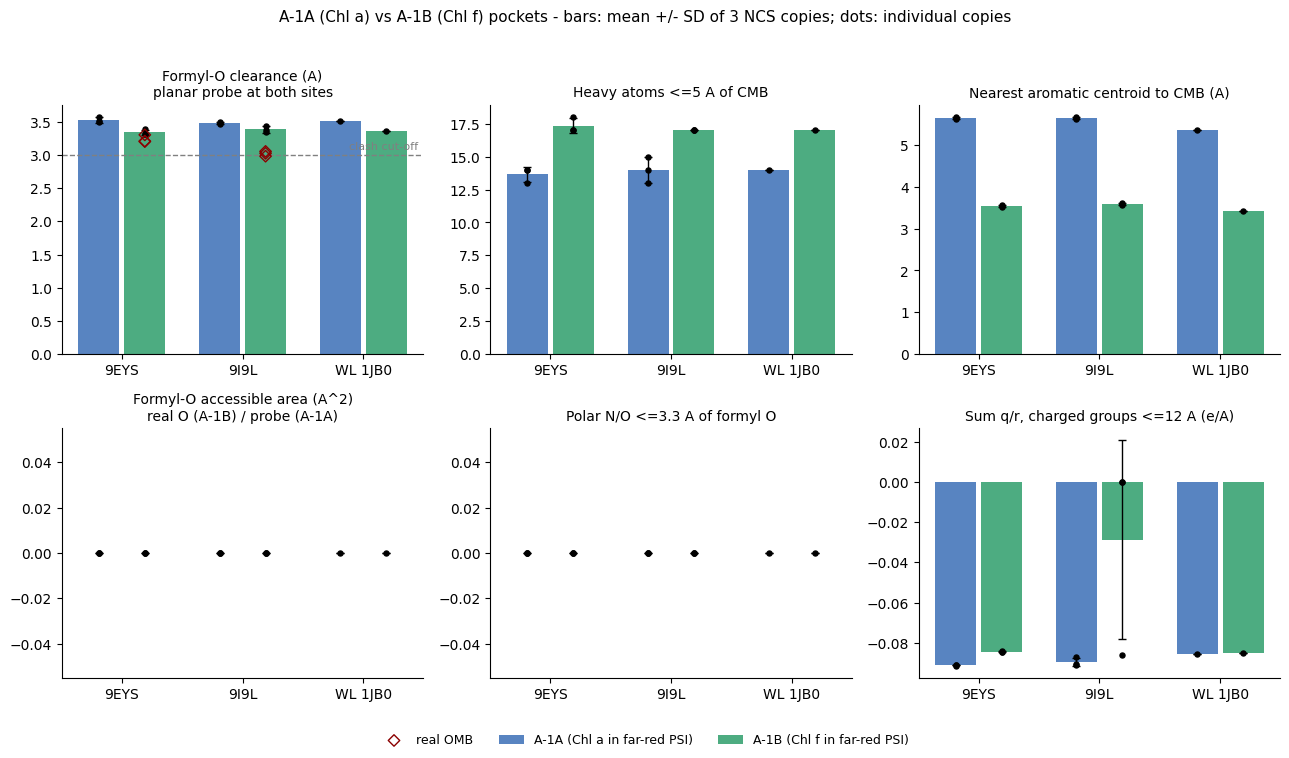


Saved to /content/drive/MyDrive/Rabia..Australia/_Staging_FINAL_v3_20261017T104635Z_51016d  (Tables / Figures / Reports) - done in 24s
Analysed: 12 sites
Saved experimental results into: /content/drive/MyDrive/Rabia..Australia/_Staging_FINAL_v3_20261017T104635Z_51016d


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_504/2575735335.py:45: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  say(f"\nSaved to {ROOT}  (Tables / Figures / Reports) - done in {(datetime.datetime.utcnow() - t0).seconds}s")


In [15]:
FRL_RESULTS, CONTRAST_RESULTS, WL_RESULTS, SUBSTITUTION_RESULTS = main()
print('Analysed:', len(FRL_RESULTS), 'sites')
print('Saved experimental results into:', STAGING_ROOT)


## Step 15 — Validate results and create an audit manifest
These are **automated structural/data checks**, not proof of the biological mechanism. The validation fails before touching earlier Drive results if input files or output files are incomplete. Note the mismatch between the ideal planar probe and real OMB if flagged.

In [16]:
import json, numpy as np, pandas as pd
from datetime import datetime, timezone

# Basic source integrity and pigment/site assignments
assert isinstance(FRL_RESULTS, pd.DataFrame) and not FRL_RESULTS.empty
assert set(FRL_RESULTS.structure) == set(FRL_IDS), 'One of the requested structures is missing'
assert set(FRL_RESULTS.site) == {'A-1A', 'A-1B'}, 'Missing one of the comparison sites'
assert (FRL_RESULTS.loc[FRL_RESULTS.site == 'A-1A','pigment'] == 'CLA').all(), 'Incorrect chlorophyll-a site assignment'
assert (FRL_RESULTS.loc[FRL_RESULTS.site == 'A-1B','pigment'] == 'F6C').all(), 'Incorrect chlorophyll-f site assignment'
for sid in FRL_IDS:
    group = FRL_RESULTS[FRL_RESULTS.structure == sid]
    assert len(group) == 6, f'Expected 3 A-1A and 3 A-1B sites for {sid}; got {len(group)}'
    assert 17 <= group.pair_mgmg.min() and group.pair_mgmg.max() <= 21, f'Site pairing Mg-Mg distances unexpected for {sid}'
assert FRL_RESULTS.loc[FRL_RESULTS.site == 'A-1B','cmb_omb'].between(1.1,1.4).all(), 'Unexpected CMB-OMB bond geometry'
assert np.isfinite(FRL_RESULTS.prb_clear).all(), 'Missing planar-probe values'
assert np.isfinite(FRL_RESULTS.ref_clear).all(), 'Missing formyl-O reference clearance values'
assert isinstance(CONTRAST_RESULTS,pd.DataFrame) and not CONTRAST_RESULTS.empty

required_outputs = {
    'Tables': ['a1_pocket_final_v3_sites.csv','a1_pocket_final_v3_contrasts.csv'],
    'Figures': ['a1_pocket_final_v3.png','a1_pocket_final_v3.pdf'],
    'Reports': ['a1_pocket_final_v3.txt']
}
for folder, names in required_outputs.items():
    for filename in names:
        path = STAGING_ROOT / folder / filename
        assert path.is_file() and path.stat().st_size > 100, f'Missing or too-small output: {path}'

# Additional warnings help the human reviewer interpret, rather than conceal, imperfections.
max_offset = float(FRL_RESULTS.loc[FRL_RESULTS.site=='A-1B','real_vs_probe_offset'].max())
notes = []
if max_offset > 0.5:
    notes.append(f'Ideal planar formyl probes deviate by as much as {max_offset:.2f} Å from the real OMB positions: interpret hypothetical-probe results cautiously.')
if WL_REF and (WL_RESULTS is None or len(WL_RESULTS)==0):
    notes.append('White-light 1JB0 comparison was requested but DID NOT complete; far-red main analysis only.')
notes.append('These three model copies per structure are not independent biological replicates.')
notes.append('Candidate hydrogen bonds are based on heavy-atom proximity and are not validated by donor-H-acceptor angles.')
notes.append('Verify A-1 site identities, residue correspondence and scientific verdict against Consoli et al. (Science, 2025).')

manifest = {
    'tag': TAG, 'run_id': RUN_ID, 'timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'structures': FRL_IDS, 'n_far_red_sites': int(len(FRL_RESULTS)),
    'n_contrast_rows': int(len(CONTRAST_RESULTS)),
    'white_light_requested': bool(WL_REF),
    'white_light_completed': bool(WL_RESULTS is not None and len(WL_RESULTS)>0),
    'passed_automated_checks': True,
    'scientific_review_notes': notes
}
(STAGING_ROOT/'Logs'/'a1_pocket_final_v3_manifest.json').write_text(json.dumps(manifest,indent=2))
(STAGING_ROOT/'Reports'/'a1_pocket_final_v3_review_notes.txt').write_text('\n'.join(notes)+'\n')
print('Automated validation: PASS')
print('Report and figures are staged, not yet installed.')
print('Scientific review notes:')
for note in notes: print(' •',note)


Automated validation: PASS
Report and figures are staged, not yet installed.
Scientific review notes:
 • Ideal planar formyl probes deviate by as much as 0.94 Å from the real OMB positions: interpret hypothetical-probe results cautiously.
 • These three model copies per structure are not independent biological replicates.
 • Candidate hydrogen bonds are based on heavy-atom proximity and are not validated by donor-H-acceptor angles.
 • Verify A-1 site identities, residue correspondence and scientific verdict against Consoli et al. (Science, 2025).


## Step 16 — Preview exactly which files will be archived
Only earlier **analysis outputs** in `Figures`, `Tables`, `Reports` and `Logs` are archived. Input structures stay where they are. Existing notebooks are archived **only if** a new FINAL-v3 `.ipynb` is already saved inside `Scripts`.

No action in this step permanently deletes data.

In [17]:
ACTIVE_DIRS = ('Figures','Tables','Reports','Logs')
SCRIPT_FOLDER = BASE_ROOT / 'Scripts'
SCRIPT_FOLDER.mkdir(exist_ok=True)

# Match all previous output versions, including v1/v2 and an earlier final-v3 rerun.
def is_prior_analysis_output(path):
    return path.is_file() and path.name.startswith(('a1_pocket_comparison_', 'a1_pocket_final_v3'))

prior_files = [(folder, p) for folder in ACTIVE_DIRS
               for p in (BASE_ROOT/folder).iterdir() if is_prior_analysis_output(p)]
new_notebook_present = any(p.is_file() and p.name.lower().endswith('.ipynb')
                           and ('final_v3' in p.name.lower() or 'final-v3' in p.name.lower())
                           for p in SCRIPT_FOLDER.iterdir())
old_notebooks = [p for p in SCRIPT_FOLDER.iterdir()
                 if p.is_file() and p.name.lower().endswith('.ipynb')
                 and 'final_v3' not in p.name.lower() and 'final-v3' not in p.name.lower()]
print('Previous analysis output files to archive:',len(prior_files))
for folder, path in prior_files: print(' BACKUP',folder, '/',path.name)
if new_notebook_present:
    print('Found new FINAL v3 notebook: earlier notebooks may also be archived.')
    for p in old_notebooks: print(' BACKUP Scripts /',p.name)
else:
    print('No FINAL v3 notebook saved in Scripts; earlier notebook(s) will be preserved for safety.')
print('Validated new result files:',sum(len(v) for v in required_outputs.values()), 'required, plus optional supplementary files')


Previous analysis output files to archive: 11
 BACKUP Figures / a1_pocket_comparison_corrected_v2_9i9l.png
 BACKUP Figures / a1_pocket_comparison_corrected_v2_9i9l.pdf
 BACKUP Figures / a1_pocket_comparison_corrected_v2_9eys.png
 BACKUP Figures / a1_pocket_comparison_corrected_v2_9eys.pdf
 BACKUP Tables / a1_pocket_comparison_corrected_v2_9i9l.csv
 BACKUP Tables / a1_pocket_comparison_corrected_v2_9eys.csv
 BACKUP Tables / a1_pocket_comparison_corrected_v2_9i9l_9eys_combined.csv
 BACKUP Reports / a1_pocket_comparison_corrected_v2_9i9l.txt
 BACKUP Reports / a1_pocket_comparison_corrected_v2_9eys.txt
 BACKUP Logs / a1_pocket_comparison_corrected_v2_9i9l.log
 BACKUP Logs / a1_pocket_comparison_corrected_v2_9eys.log
No FINAL v3 notebook saved in Scripts; earlier notebook(s) will be preserved for safety.
Validated new result files: 5 required, plus optional supplementary files


## Step 17 — Activate FINAL v3 safely: BACK UP old results, then replace
If `AUTO_ACTIVATE_FINAL_V3 = True`, **Run all** executes this automatically after Step 15 has passed. To keep everything staged, set it to `False` in Step 3.

This does not permanently delete the old outputs: it moves them to a timestamped `Old_Version_Backup/` subfolder with the same folder names. In the unlikely event that activation fails, the script attempts to restore the old files.

In [18]:
import shutil

if not AUTO_ACTIVATE_FINAL_V3:
    print('Activation disabled. Existing results remain untouched; change Step 3 to True when ready.')
else:
    if not manifest.get('passed_automated_checks'):
        raise RuntimeError('Validation not complete: refusing to replace earlier results.')
    BACKUP_ROOT = BASE_ROOT / 'Old_Version_Backup' / f'Before_FINAL_v3_{RUN_ID}'
    if BACKUP_ROOT.exists():
        raise FileExistsError('Backup folder for this run already exists; refusing to overwrite it.')
    BACKUP_ROOT.mkdir(parents=True, exist_ok=False)
    moved, added = [], []
    try:
        # Re-check actual live files, not only the previous preview.
        to_archive = [(folder,p) for folder in ACTIVE_DIRS
                      for p in (BASE_ROOT/folder).iterdir() if is_prior_analysis_output(p)]
        if new_notebook_present:
            to_archive += [('Scripts',p) for p in old_notebooks if p.exists()]
        for folder, src in to_archive:
            dest = BACKUP_ROOT / folder / src.name
            dest.parent.mkdir(parents=True, exist_ok=True)
            if dest.exists(): raise FileExistsError(dest)
            shutil.move(str(src), str(dest))
            moved.append((src,dest))
        # Install only staged result files. Keep the original protein CIFs unchanged.
        for folder in ACTIVE_DIRS:
            for src in sorted((STAGING_ROOT / folder).iterdir()):
                if not src.is_file(): continue
                dest = BASE_ROOT / folder / src.name
                if dest.exists(): raise FileExistsError(f'Unarchived file would be overwritten: {dest}')
                added.append(dest)
                shutil.copy2(src, dest)
        # Preserve white-light reference (only if downloaded successfully and not already present).
        if WL_REF:
            wl_src = STAGING_ROOT/'Structures'/f'{WL_REF.lower()}.cif'
            wl_dst = BASE_ROOT/'Structures'/f'{WL_REF.lower()}.cif'
            if wl_src.exists() and not wl_dst.exists():
                added.append(wl_dst); shutil.copy2(wl_src,wl_dst)
        for folder, names in required_outputs.items():
            for name in names:
                dest = BASE_ROOT/folder/name
                if not dest.exists() or dest.stat().st_size <= 100: raise RuntimeError(f'Activation copy failed: {dest}')
        audit = {'backup_folder':str(BACKUP_ROOT), 'backed_up_files':len(moved),
                 'activated_files':[str(p.relative_to(BASE_ROOT)) for p in added], 'manifest':manifest}
        audit_path = BASE_ROOT/'Logs'/'a1_pocket_final_v3_activation.json'
        added.append(audit_path)
        audit_path.write_text(json.dumps(audit,indent=2))
        # Remove ONLY this run's validated temporary staging copies after all outputs are installed.
        # Never remove the active project folder or any historical backup.
        if STAGING_ROOT.parent.resolve() == BASE_ROOT.resolve() and STAGING_ROOT.name.startswith('_Staging_FINAL_v3_'):
            shutil.rmtree(STAGING_ROOT)
        print('ACTIVATION COMPLETE')
        print('Previous files safely moved to:',BACKUP_ROOT)
        print('Previous files archived:',len(moved))
        print('New v3 files installed:',len(added))
        print('Source structures remain safe in',BASE_ROOT/'Structures')
    except Exception:
        print('Activation failed: attempting to restore previous files.')
        for p in reversed(added):
            if p.is_file(): p.unlink()
        for orig,bak in reversed(moved):
            if bak.exists():
                orig.parent.mkdir(parents=True,exist_ok=True)
                shutil.move(str(bak),str(orig))
        raise


ACTIVATION COMPLETE
Previous files safely moved to: /content/drive/MyDrive/Rabia..Australia/Old_Version_Backup/Before_FINAL_v3_20261017T104635Z_51016d
Previous files archived: 11
New v3 files installed: 10
Source structures remain safe in /content/drive/MyDrive/Rabia..Australia/Structures


## Step 18 — Final audit and outputs
Check the active folders. Existing structures are preserved; old V1/V2 result files are in `Old_Version_Backup` after successful activation. Move this final notebook itself to `Rabia..Australia/Scripts` if you have not already saved it there.

In [19]:
print('Main project folder:', BASE_ROOT)
for folder in ('Structures','Figures','Tables','Reports','Logs','Scripts'):
    base=BASE_ROOT/folder
    names=sorted(p.name for p in base.iterdir() if p.is_file())
    print(f'\n{folder} ({len(names)} files):')
    for name in names: print('  ',name)
print('\nBackups:', BASE_ROOT/'Old_Version_Backup')
print('\nReminder: save this notebook itself to Scripts and have the biology validated before publication.')


Main project folder: /content/drive/MyDrive/Rabia..Australia

Structures (3 files):
   1jb0.cif
   9eys.cif
   9i9l.cif

Figures (2 files):
   a1_pocket_final_v3.pdf
   a1_pocket_final_v3.png

Tables (3 files):
   a1_pocket_final_v3_contrasts.csv
   a1_pocket_final_v3_pocket_substitutions.csv
   a1_pocket_final_v3_sites.csv

Reports (2 files):
   a1_pocket_final_v3.txt
   a1_pocket_final_v3_review_notes.txt

Logs (2 files):
   a1_pocket_final_v3_activation.json
   a1_pocket_final_v3_manifest.json

Scripts (1 files):
   A_1_Chlorophyll.ipynb

Backups: /content/drive/MyDrive/Rabia..Australia/Old_Version_Backup

Reminder: save this notebook itself to Scripts and have the biology validated before publication.
